# ARAI synthetic data generation

This notebook builds one synthetic *world* for the ARAI return-abuse demonstration, stage by stage, and then
checks the result. It follows `final-spec/components/02-synthetic-data-generation.md` (specification v1.1).

**What a world is.** A snapshot of an Indian online apparel retailer on 9 September 2026 with twelve months of
history: customers, orders, deliveries and return requests over the fixed 300-SKU catalog. Most returns are
honest. A small share of accounts also make deceptive claims or temporary-use returns, alone or in rings.

**Two outputs, kept apart.**
- *Operational tables* (seven CSV files plus a manifest): what a retailer would actually hold. This is the
  only thing the model and the application may read.
- *Private truth*: who abused, which unit was defective, which accounts form a household or a ring. It is
  written under a separate root and is used only for training labels and evaluation.

**How to run.** From the project root: `uv sync`, then `uv run jupyter lab` and run all cells. The generator
code lives in `src/arai/generator/`; this notebook calls it one stage at a time so each stage can be inspected.

## 1. Parameters

In [1]:
SEED = 2001           # fixture seeds 2001-2003 give 1,000 customers; train 2101-2110, validation 2201-2205,
                      # test 2301-2305 and demo 2401 give 10,000 (contracts/experiment.yaml)
N_CUSTOMERS = None    # None = the size defined for the seed
WRITE_TO_DISK = True  # writes under data/ (ignored by git; reproducible from seed, spec and lock file)

In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import pandas as pd
from IPython.display import display

from arai import diagnostics
from arai.generator import WorldBuilder, generate_world, write_world
from arai.validation import validate_world

pd.set_option("display.max_columns", 40, "display.width", 200, "display.precision", 3)

# chart style: quiet surface and axes, thin marks, two validated series colours
SURFACE, INK, SECONDARY, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, QUIET = "#2a78d6", "#eb6834", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK, "axes.labelcolor": SECONDARY,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": SECONDARY, "ytick.labelcolor": SECONDARY,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "legend.frameon": False, "axes.titlelocation": "left",
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

## 2. Inputs: the catalog and the settings

The catalog is the team's 300-SKU file. A named adapter renames three columns and turns the two boolean
columns into 0/1. Nothing else is changed, and the source file's hash is recorded.

In [3]:
builder = WorldBuilder(SEED, N_CUSTOMERS)
ctx, catalog, settings = builder.ctx, builder.ctx.catalog, builder.ctx.s

print("world:", ctx.world_id, "| customers:", ctx.n, "| purpose:", settings.purpose_of(SEED))
print("history:", settings.history_start, "to", settings.snapshot_date, "| cutoff:", settings.cutoff.isoformat())
print("catalog source sha256:", catalog.source_sha256[:16], "...")
print("adapter transforms:", "; ".join(catalog.transforms))
display(catalog.sku_master.head(4))
display(catalog.styles.groupby("category").agg(styles=("style_id", "size"), skus=("skus", "sum"),
                                                median_price=("median_price", "median"),
                                                occasion_styles=("is_occasion_wear", "sum")))

world: W2001 | customers: 1000 | purpose: fixture
history: 2025-09-10 to 2026-09-09 | cutoff: 2026-09-09T23:59:59+05:30
catalog source sha256: 0a558c72b1c4e108 ...
adapter transforms: rename sku_id->sku; rename color->colour; rename color_id->colour_id; is_occasion_wear True/False->1/0; active_flag True/False->1/0


,sku,style_id,brand,category,size,colour,colour_id,unit_price,price_band,return_window_days,is_occasion_wear,launch_date,active_flag
0,SKU001,BA-JNS-01,Brand_A,Jeans,L,Black,C001,1599.0,Mid,30,0,2024-04-18,1
1,SKU002,BA-JNS-01,Brand_A,Jeans,M,Black,C001,1599.0,Mid,30,0,2024-04-18,1
2,SKU003,BA-JNS-01,Brand_A,Jeans,L,Grey,C004,1599.0,Mid,30,0,2024-04-18,1
3,SKU004,BA-JNS-01,Brand_A,Jeans,M,Grey,C004,1599.0,Mid,30,0,2024-04-18,1


,styles,skus,median_price,occasion_styles
category,,,,
Dress,5,38,4299.0,4
Jacket,7,58,3099.0,1
Jeans,7,62,1899.0,0
Shirt,8,64,1549.0,1
T-shirt,10,78,1349.0,0


## 3. Stage 1: customer profiles and abuse propensity (private)

Each account gets a persona, a tenure, an order target, a festive share and an honest return propensity from
`assets/profile-config.yaml`. These are generation targets, not model inputs, and they never leave the private
truth.

Abuse propensity is drawn separately. Expected whole-world rates are 4% for deceptive claims, 3% for
temporary use and 0.5% for both. They are probabilities, not quotas, so a small world can land some way off.
Honest return propensity is independent of abuse propensity.

In [4]:
profiles = builder.build_profiles()
by_persona = profiles.groupby("persona").agg(
    accounts=("customer_id", "size"), median_order_target=("target_order_count", "median"),
    mean_return_propensity=("target_return_propensity", "mean"), heavy_return_overlay=("heavy_return_overlay", "sum"),
    claim_propensity=("claim_propensity", "sum"), temporary_use_propensity=("temporary_use_propensity", "sum"))
display(by_persona)
print("propensity shares, expected 0.040 / 0.030 / 0.005:",
      round(profiles["claim_propensity"].mean(), 3), "/", round(profiles["temporary_use_propensity"].mean(), 3), "/",
      round((profiles["claim_propensity"] & profiles["temporary_use_propensity"]).mean(), 3))

,accounts,median_order_target,mean_return_propensity,heavy_return_overlay,claim_propensity,temporary_use_propensity
persona,,,,,,
Dormant,115,0.0,0.000,0,0,0
High_Intensity,24,20.0,0.437,3,1,1
Loyalist,167,22.0,0.156,13,7,2
New_Growth,150,4.0,0.145,13,12,3
Occasional,370,2.0,0.124,19,12,3
Seasonal,174,12.0,0.225,6,11,4


propensity shares, expected 0.040 / 0.030 / 0.005: 0.043 / 0.013 / 0.003


## 4. Stage 2: households, rings and shared locations (private)

- **Households**: 12% of accounts, groups of 2-5. They always share an address and often a device or payment method.
- **Coordination groups (rings)**: 40% of the accounts with any abuse propensity, groups of 3-6.
- **Shared locations**: a hostel or office address shared by 26-60 otherwise unrelated accounts.

Membership is private. The operational data only shows which address, device and payment identifier each order
used, and every member uses a shared identifier only some of the time. Sharing is not guilt: households and
rings look alike in the identifiers.

In [5]:
rel = builder.build_relationships()
groups = pd.DataFrame([{"group_type": g["type"], "size": len(g["members"])} for g in rel.groups.values()])
display(groups.groupby("group_type")["size"].agg(groups="size", members="sum", smallest="min", largest="max"))
display(rel.truth.groupby(["group_type", "identifier_type"]).agg(
    groups=("group_id", "nunique"), mean_usage_probability=("sampled_usage_probability", "mean")))

,groups,members,smallest,largest
group_type,,,,
coordination,4,19,3,6
household,30,119,2,5
shared_location,1,26,26,26


groups  mean_usage_probability
group_type      identifier_type                                
coordination    address               2                   0.834
                device                4                   0.885
                payment               4                   0.840
household       address              30                   0.740
                device               24                   0.762
                payment               5                   0.719
shared_location address               1                   0.756

## 5. Stage 3: base purchases and delivery

Orders are spread over each account's eligible days, with festive windows weighted up. Each order has
`min(6, 1 + Poisson(0.6))` lines; a line is a uniform style and then a uniform SKU already launched on that day.
Fulfilment gives each line one of five states as seen at the cutoff. A plan that completes after the cutoff
(a parcel still in transit, a cancellation not yet made) stays private.

In [6]:
started = time.time()
orders, lines = builder.build_orders()
print(f"{len(orders):,} orders, {len(lines):,} lines, {len(builder.units):,} delivered units in {time.time() - started:.1f}s")
display(lines["line_status"].value_counts(normalize=True).rename("share of lines").to_frame().T)

10,114 orders, 16,081 lines, 16,311 delivered units in 0.4s


line_status,delivered,shipped,cancelled,awaiting_dispatch,lost_in_transit
share of lines,0.932,0.031,0.027,0.008,0.002


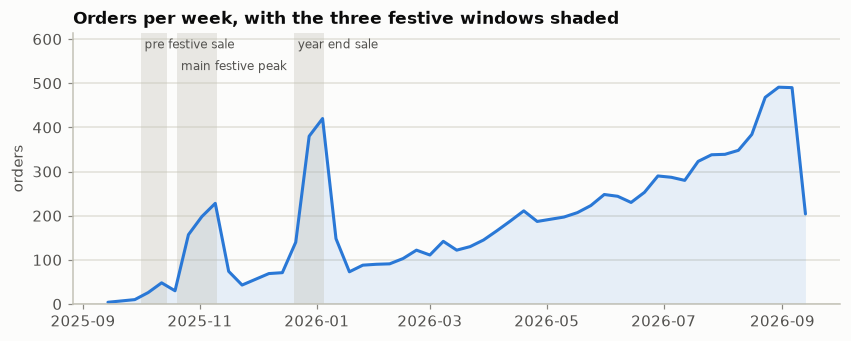

In [7]:
weekly = orders.set_index("order_date").resample("W").size()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(weekly.index, weekly.values, color=BLUE)
ax.fill_between(weekly.index, weekly.values, color=BLUE, alpha=0.10, linewidth=0)
top = weekly.max() * 1.25
for position, window in enumerate(settings.festive_windows):
    start = pd.Timestamp(f"2025-{window['start']}")
    end = pd.Timestamp(f"{2026 if window.get('crosses_year') else 2025}-{window['end']}")
    ax.axvspan(start, end, color=QUIET, alpha=0.35, linewidth=0)
    # stagger the labels so neighbouring windows do not collide
    ax.text(start, top * (0.98 - 0.08 * (position % 2)), " " + window["name"].replace("_", " ").lower(), ha="left", va="top",
            fontsize=8, color=SECONDARY)
ax.set_ylim(0, top)
ax.set_title("Orders per week, with the three festive windows shaded")
ax.set_ylabel("orders")
ax.grid(axis="x", visible=False)
plt.show()

## 6. Stage 4: honest returns

Every delivered unit can be returned for an honest reason, resolved once per unit in this priority:

1. a genuine fulfilment failure (parcel not received, wrong item, missing parts, empty package), about 1.5% of
   units, clustered by delivery address;
2. carrier damage, about 0.5%;
3. a defective unit from a defect-prone style;
4. ordinary fit or preference.

Honest requests reserve their units. Abuse is added afterwards from separate random streams and can only use
units that are still unreserved, which is why switching abuse off leaves every honest request unchanged.

In [8]:
honest = builder.build_honest_returns()
display(honest.groupby("cause").agg(requests=("event_id", "size"), units=("quantity", "sum"),
                                    visible_at_cutoff=("visible", "sum"), late=("late", "sum")))
display(honest.loc[honest["visible"], "line_status"].value_counts(normalize=True).rename("share of visible honest requests").to_frame().T)
defect_styles = catalog.styles.loc[builder.defect_prone, ["style_id", "category"]]
print("defect-prone styles in this world (private):", ", ".join(defect_styles["style_id"]) or "none")
multipliers = pd.Series(builder.g_address)
print(f"address failure multiplier: mean {multipliers.mean():.2f}, share above 4x {(multipliers > 4).mean():.1%}")

,requests,units,visible_at_cutoff,late
cause,,,,
carrier_damage,83,83,74,3
genuine_fulfilment_failure,209,209,200,0
latent_defect,191,193,175,6
ordinary_fit_preference,2665,2720,2403,49


line_status,refunded,pending,rejected,withdrawn
share of visible honest requests,0.891,0.049,0.031,0.028


defect-prone styles in this world (private): BB-TSH-01, BB-TSH-02, BC-TSH-03
address failure multiplier: mean 0.92, share above 4x 3.4%


## 7. Stage 5: the abuse layer

**Ring campaigns.** The world has a private hot list of four target styles, weighted by price. Each ring picks
one or two of them and two to four campaign dates. On a campaign date each claim-capable member takes part with
probability 0.6: the member reuses a recent purchase of that style if there is one, otherwise places a
*campaign order* for it, and then files a deceptive claim a few days after delivery. Campaign orders are marked
only in private truth. An attempt that cannot complete (the member had not signed up yet, the parcel is not
delivered by the cutoff, and so on) is kept with its reason and never retried.

**Solo actions.** Every account with a propensity has its own action rate (mean 0.20, widely spread, so some
abusers act once a year and some often). Deceptive claims use that rate per delivered order. Temporary use
favours orders that contain occasion wear.

In [9]:
actions = builder.build_abuse()
hot = catalog.styles.iloc[builder.hot_list][["style_id", "category", "median_price", "is_occasion_wear"]]
print("hot-list styles (private):"); display(hot)
print(f"{len(builder.campaign_truth)} campaign dates across "
      f"{builder.campaign_truth['coordination_group_id'].nunique()} rings")
if len(actions):
    display(actions.assign(scope=np.where(actions["campaign_id"].notna(), "ring campaign", "solo"))
                   .groupby(["scope", "action_type", "completed_action"]).size().unstack(fill_value=0))
    display(actions.loc[~actions["completed_action"], "uncompleted_reason"].value_counts().rename("uncompleted attempts").to_frame().T)

hot-list styles (private):


,style_id,category,median_price,is_occasion_wear
1,BA-JNS-02,Jeans,1699.0,0
15,BB-SHT-03,Shirt,2499.0,1
21,BC-JNS-01,Jeans,1899.0,0
30,BD-JNS-02,Jeans,2899.0,0


12 campaign dates across 4 rings


completed_action                          False  True 
scope         action_type                             
ring campaign deceptive_contents_claim        6      6
              deceptive_nonreceipt_claim     10      6
solo          deceptive_contents_claim        4     20
              deceptive_nonreceipt_claim      6     37
              temporary_use_return            2     25

uncompleted_reason,pre_signup,no_unreserved_unit,request_after_cutoff
uncompleted attempts,16,10,2


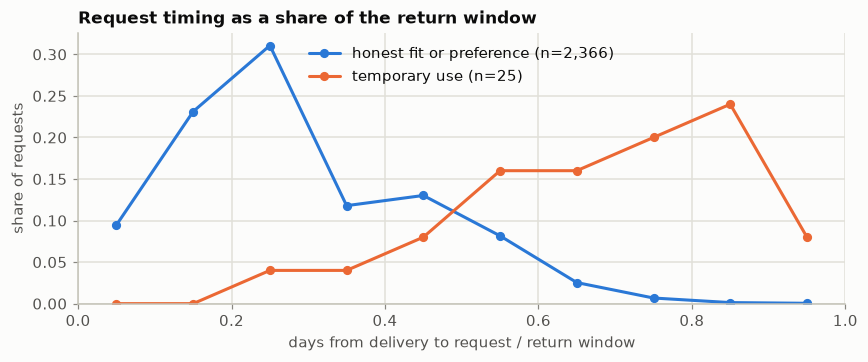

In [10]:
# Where in the return window do requests arrive? Honest returns come early; temporary use comes late.
events = pd.concat([builder.honest_events, builder.abusive_events], ignore_index=True)
events = events[events["visible"].astype(bool) & ~events["late"].astype(bool)]
ratio = events["latency_days"] / events["window"]
series = {"honest fit or preference": (ratio[events["cause"] == "ordinary_fit_preference"], BLUE),
          "temporary use": (ratio[events["cause"] == "temporary_use_return"], ORANGE)}
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(9, 3.2))
for label, (values, colour) in series.items():
    if len(values):
        share = np.histogram(values, bins=bins)[0] / len(values)
        ax.plot((bins[:-1] + bins[1:]) / 2, share, color=colour, marker="o", markersize=5, label=f"{label} (n={len(values):,})")
ax.set_title("Request timing as a share of the return window")
ax.set_xlabel("days from delivery to request / return window")
ax.set_ylabel("share of requests")
ax.set_xlim(0, 1); ax.set_ylim(bottom=0)
ax.legend(loc="upper center")
plt.show()

## 8. Stage 6: the snapshot and the private truth

`finalize()` keeps only what is observable at the cutoff, consolidates return requests into headers and builds
the seven operational tables. Tables are sorted by primary key and identifiers are hash-derived, so neither row
order nor an identifier can reveal whether a row is honest, abusive or a campaign order.

In [11]:
world = builder.finalize()
display(pd.Series(world.summary, name="rows").to_frame().T)
for name in ("sales_order", "sales_order_line", "return_order", "return_order_line"):
    print(name); display(world.tables[name].head(3))
print("private truth tables:", {name: len(table) for name, table in world.truth.items()})

,customer_master,sku_master,reason_code,sales_order,sales_order_line,return_order,return_order_line
rows,1000,300,16,10126,16093,2618,2946


sales_order


,order_id,customer_id,order_date,channel,address_id,device_id,payment_id,currency,order_subtotal,order_shipping,order_total
0,W2001-O0000A231BB6F,W2001-C00745,2026-07-23,web,W2001-A68F659C5C80D,W2001-D198ECEF8CD63,W2001-P4507CC073CC2,INR,3058.15,0.0,3058.15
1,W2001-O0013C3AD8B23,W2001-C00444,2025-11-30,mobile_app,W2001-A5D5F2D77C43A,W2001-D2C31F08DDD76,W2001-P0E91BE14E718,INR,6133.15,0.0,6133.15
2,W2001-O00154194DE73,W2001-C00444,2025-11-08,web,W2001-A5D5F2D77C43A,W2001-D2C31F08DDD76,W2001-P0E91BE14E718,INR,5252.60,0.0,5252.60


sales_order_line


,order_id,order_line_no,sku,quantity,unit_price,line_discount,line_total,return_window_days,line_status,shipped_date,delivered_date
0,W2001-O0000A231BB6F,1,SKU011,1,1699.0,0.00,1699.00,30,delivered,2026-07-24,2026-07-31
1,W2001-O0000A231BB6F,2,SKU115,1,1599.0,239.85,1359.15,30,delivered,2026-07-24,2026-07-31
2,W2001-O0013C3AD8B23,1,SKU223,1,3499.0,0.00,3499.00,60,delivered,2025-12-01,2025-12-08


return_order


,return_order_id,customer_id,return_created_at,return_channel,refund_method,refund_total,available_at
0,W2001-R0005833011FF,W2001-C00039,2026-08-26 17:32:33,courier_pickup,original_payment,2634.15,2026-08-26 17:32:33
1,W2001-R0013537E6F56,W2001-C00923,2026-01-22 22:54:29,courier_pickup,store_credit,0.00,2026-01-22 22:54:29
2,W2001-R002C91FD7253,W2001-C00497,2026-02-27 12:02:11,courier_pickup,store_credit,0.00,2026-02-27 12:02:11


return_order_line


,return_order_id,return_line_no,order_id,order_line_no,sku,quantity_returned,reason_code,requested_at,available_at,line_status,refund_amount,return_received_flag,reason_text,disposition
0,W2001-R0005833011FF,1,W2001-O55CA3AE55C25,2,SKU102,1,didnt_fit,2026-08-26 17:32:33,2026-08-26 17:32:33,refunded,2634.15,1,None,None
1,W2001-R0013537E6F56,1,W2001-OD53DD8BF23E2,1,SKU210,1,missing_parts,2026-01-22 22:54:29,2026-01-22 22:54:29,rejected,0.00,0,None,None
2,W2001-R002C91FD7253,1,W2001-O1328D8CC59F7,2,SKU135,1,late_delivery,2026-02-27 12:02:11,2026-02-27 12:02:11,rejected,0.00,0,None,None


private truth tables: {'customer_profile': 1000, 'unit_truth': 16323, 'campaign': 12, 'relationship_truth': 307, 'unit_allocation': 3301, 'action_truth': 122, 'customer_truth': 1000, 'product_truth': 37, 'sku_truth': 300, 'line_truth': 15006, 'order_truth': 10126, 'address_truth': 789}


## 9. Write to disk and validate

The operational CSV files and `manifest.json` go under `data/artifacts/worlds/<world>/operational/`, with
Parquet copies beside them. Private truth goes under `data/private/<world>/`, a separate root that the serving
process will never mount. The validator then checks the written files against `contracts/data-schema.yaml`:
columns, types, keys, references, ownership, money, quantities and chronology. Any structural failure rejects
the whole world.

In [12]:
if WRITE_TO_DISK:
    out = write_world(world)
    report = validate_world(out["operational"])
    print("operational:", out["operational"]); print("private:    ", out["private"])
    print("validation accepted:", report.accepted, "| violations:", len(report.violations))
    assert report.accepted, report.violations
    display(pd.DataFrame(out["manifest"]["files"]).T[["row_count", "sha256"]].assign(sha256=lambda f: f["sha256"].str[:16] + "..."))
    print(json.dumps(out["manifest"]["generator"], indent=1))

operational: F:\projects\Adaptive_Return_Abuser_Intelliengence\data\artifacts\worlds\W2001\operational
private:     F:\projects\Adaptive_Return_Abuser_Intelliengence\data\private\W2001
validation accepted: True | violations: 0


,row_count,sha256
customer_master,1000,444cd8b58c015146...
sku_master,300,27048143e1f617dc...
reason_code,16,c3e219f89cd51f5a...
sales_order,10126,1661a9d96ccbcd9b...
sales_order_line,16093,e85cb08ae728a29e...
return_order,2618,a68462c440947823...
return_order_line,2946,bb90afdbfafff80e...


{
 "name": "arai.generator",
 "version": "0.1.0",
 "seed": 2001,
 "config_sha256": "746abd4bacc64f10c2e2dd9f3b28b881199dc7c5d61bcebfa16c619ea0f73367",
 "catalog_sha256": "0a558c72b1c4e108d4d114ec72f3480bc72597d05282979ded4087cbcdb53a3e",
 "dependency_lock_sha256": "1d7e8d9a459989a8df836a9883d718cd9253d5cb736f6b3e7a310582f67b97eb",
 "code_sha256": "8a4f530372e880a64383764814e0db9d72066377d6cfb83dfcb9c671cb3d157c"
}


## 10. Diagnostics: did the world come out as intended?

Everything from here on joins private truth, so it is for development worlds only. The first table compares
realised rates with the configured targets. Targets are not quotas, so small differences are expected,
especially in a 1,000-customer fixture world.

In [13]:
report_card = diagnostics.generation_report(world)
units, profile, returns = world.truth["unit_truth"], world.truth["customer_profile"], world.tables["return_order_line"]
accepted = settings.accepted
propensity = profile[profile["claim_propensity"] | profile["temporary_use_propensity"]]
rates = np.r_[propensity.loc[propensity["claim_propensity"], "claim_action_rate"],
              propensity.loc[propensity["temporary_use_propensity"], "temporary_use_action_rate"]]
checks = pd.DataFrame([
    ("claim propensity (all accounts)", 0.04, profile["claim_propensity"].mean()),
    ("temporary-use propensity (all accounts)", 0.03, profile["temporary_use_propensity"].mean()),
    ("both propensities", 0.005, (profile["claim_propensity"] & profile["temporary_use_propensity"]).mean()),
    ("mean action rate of propensity accounts", accepted["action_rate_mean_per_relevant_order"], rates.mean() if len(rates) else np.nan),
    ("genuine fulfilment failure per delivered unit", sum(accepted["genuine_claim_rates"].values()), units["genuine_fulfilment_cause"].notna().mean()),
    ("carrier damage per delivered unit", accepted["carrier_damage_rate"], units["carrier_damage"].mean()),
    ("cancelled lines", accepted["cancel_probability"], (world.tables["sales_order_line"]["line_status"] == "cancelled").mean()),
    ("household members", accepted["household_member_share"], world.truth["customer_truth"]["household_id"].notna().mean()),
    ("heavy-return overlay", accepted["heavy_return_share"], profile["heavy_return_overlay"].mean()),
], columns=["measure", "target", "realised"])
display(checks.style.format({"target": "{:.4f}", "realised": "{:.4f}"}).hide(axis="index"))

measure,target,realised
claim propensity (all accounts),0.0400,0.0430
temporary-use propensity (all accounts),0.0300,0.0130
both propensities,0.0050,0.0030
mean action rate of propensity accounts,0.2000,0.2030
genuine fulfilment failure per delivered unit,0.0150,0.0128
carrier damage per delivered unit,0.0050,0.0051
cancelled lines,0.0300,0.0273
household members,0.1200,0.1190
heavy-return overlay,0.0600,0.0540


In [14]:
summary = diagnostics.customer_summary(world)
eligible = summary[summary["eligible"]]
print(f"eligible (at least 3 mature sale lines): {len(eligible):,} of {len(summary):,} ({len(eligible) / len(summary):.1%})")
print(f"abusers (at least one completed abusive action): {int(summary['y_abuse'].sum())} in total, "
      f"{int(eligible['y_abuse'].sum())} eligible, {int(summary['y_abuse'].sum() - eligible['y_abuse'].sum())} excluded for thin history")
print(f"prevalence among eligible customers: {eligible['y_abuse'].mean():.1%}")
done = world.truth["action_truth"].query("completed_action").groupby("customer_id").size()
if len(done):
    print(f"completed actions per abuser: median {done.median():.0f}, one-off abusers {(done == 1).mean():.0%}")
display(eligible.groupby("persona").agg(eligible=("customer_id", "size"), abusers=("y_abuse", "sum"),
                                        mean_return_rate=("raw_return_rate", "mean")))

eligible (at least 3 mature sale lines): 548 of 1,000 (54.8%)
abusers (at least one completed abusive action): 32 in total, 25 eligible, 7 excluded for thin history
prevalence among eligible customers: 4.6%
completed actions per abuser: median 2, one-off abusers 28%


,eligible,abusers,mean_return_rate
persona,,,
High_Intensity,14,1,0.384
Loyalist,165,8,0.178
New_Growth,64,2,0.162
Occasional,161,3,0.140
Seasonal,144,11,0.267


### Why a return-rate rule struggles

The rule ranks eligible customers by raw return rate and reviews the top 5%. The chart shows the problem: abusers
do return more on average, but the two distributions overlap heavily, and the top of the ranking is full of
honest customers with a short history and one or two returns.

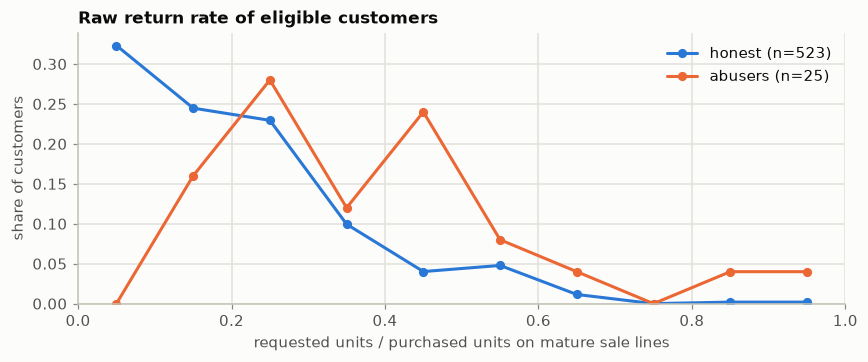

,k,true_positives,precision,recall,eligible_positives
rank by raw return rate,28.0,5.0,0.179,0.2,25.0
rank by number of claims,28.0,10.0,0.357,0.4,25.0


eligible customers with two or more claims: 42 honest, 18 abusers


In [15]:
fig, ax = plt.subplots(figsize=(9, 3.2))
bins = np.linspace(0, 1, 11)
for label, mask, colour in (("honest", eligible["y_abuse"] == 0, BLUE), ("abusers", eligible["y_abuse"] == 1, ORANGE)):
    values = eligible.loc[mask, "raw_return_rate"]
    if len(values):
        share = np.histogram(values, bins=bins)[0] / len(values)
        ax.plot((bins[:-1] + bins[1:]) / 2, share, color=colour, marker="o", markersize=5, label=f"{label} (n={len(values):,})")
ax.set_title("Raw return rate of eligible customers")
ax.set_xlabel("requested units / purchased units on mature sale lines")
ax.set_ylabel("share of customers")
ax.set_xlim(0, 1); ax.set_ylim(bottom=0)
ax.legend(loc="upper right")
plt.show()

summary["claim_count"] = summary["claim_lines"]
rules = pd.DataFrame({"rank by raw return rate": diagnostics.precision_at(world, summary, "raw_return_rate"),
                      "rank by number of claims": diagnostics.precision_at(world, summary, "claim_count")}).T
display(rules)
honest_repeat = int(((summary["y_abuse"] == 0) & summary["eligible"] & (summary["claim_lines"] >= 2)).sum())
abuser_repeat = int(((summary["y_abuse"] == 1) & summary["eligible"] & (summary["claim_lines"] >= 2)).sum())
print(f"eligible customers with two or more claims: {honest_repeat} honest, {abuser_repeat} abusers")

These two rules are quick references on one world, not the evaluation. The proper scorecard (five candidate
models, the analyst rulebook, the volume-only model and the 5% gate) is built later on the training and
validation worlds. In a 1,000-customer fixture the review list is only a few dozen customers, so these
numbers move a lot between seeds.

### Style evidence

For each style: the share of returned units with a quality reason (`damage_share`), and the share of claims
that come from linked accounts claiming on the same style within seven days (`linked_claim_share`). A style
shows a *quality* signal at damage share 0.30 or more, and a *targeting* signal with at least three linked
claimants and a linked-claim share of 0.10 or more. Both thresholds are engineering defaults to confirm on
development worlds.

In [16]:
evidence = diagnostics.style_evidence(world)
columns = ["style_id", "category", "mature_sale_lines", "return_rate", "damage_share", "claim_lines", "linked_claimers",
           "linked_claim_share", "state", "defect_state", "hot_listed", "targeting_level"]
notable = evidence[(evidence["defect_state"] == "defect_prone") | evidence["hot_listed"] | (evidence["state"] != "no_elevated_signal")]
display(notable[columns].sort_values("linked_claim_share", ascending=False))
display(pd.crosstab([evidence["defect_state"], evidence["targeting_level"]], evidence["state"]))

,style_id,category,mature_sale_lines,return_rate,damage_share,claim_lines,linked_claimers,linked_claim_share,state,defect_state,hot_listed,targeting_level
15,BB-SHT-03,Shirt,319,0.237,0.024,21,3.0,0.381,targeting,ordinary,True,targeted
1,BA-JNS-02,Jeans,321,0.172,0.017,4,0.0,0.000,no_elevated_signal,ordinary,True,none
16,BB-TSH-01,T-shirt,315,0.209,0.370,8,0.0,0.000,quality,defect_prone,False,none
17,BB-TSH-02,T-shirt,318,0.234,0.444,3,0.0,0.000,quality,defect_prone,False,none
21,BC-JNS-01,Jeans,308,0.178,0.000,5,0.0,0.000,no_elevated_signal,ordinary,True,none
25,BC-TSH-03,T-shirt,311,0.178,0.426,10,0.0,0.000,quality,defect_prone,False,none
30,BD-JNS-02,Jeans,322,0.231,0.050,9,0.0,0.000,no_elevated_signal,ordinary,True,sub_threshold


state                         no_elevated_signal  quality  targeting
defect_state targeting_level                                        
defect_prone none                              0        3          0
ordinary     none                             32        0          0
             sub_threshold                     1        0          0
             targeted                          0        0          1

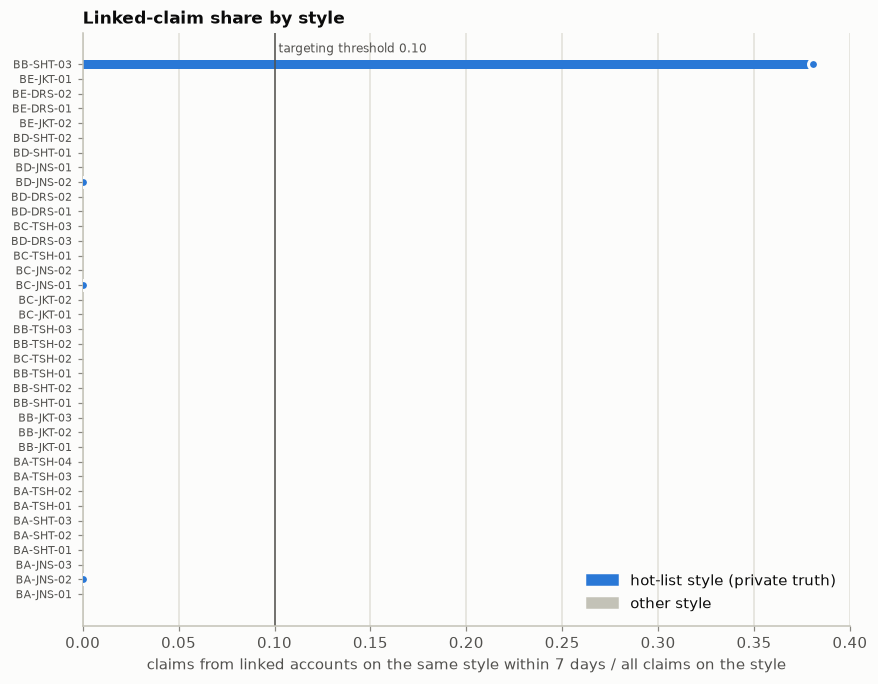

In [17]:
ordered = evidence.sort_values("linked_claim_share", na_position="first")
fig, ax = plt.subplots(figsize=(9, 7))
share = ordered["linked_claim_share"].fillna(0)
ax.barh(ordered["style_id"], share, height=0.62, color=np.where(ordered["hot_listed"], BLUE, QUIET))
hot_rows = ordered["hot_listed"].to_numpy()
# an end-dot keeps a hot-list style visible even when its share is zero
ax.scatter(share[hot_rows], ordered["style_id"][hot_rows], s=42, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
ax.axvline(0.10, color=SECONDARY, linewidth=1)
ax.text(0.10, len(ordered) - 0.4, " targeting threshold 0.10", va="bottom", fontsize=8, color=SECONDARY)
ax.legend(handles=[Patch(color=BLUE, label="hot-list style (private truth)"), Patch(color=QUIET, label="other style")],
          loc="lower right")
ax.set_title("Linked-claim share by style")
ax.set_xlabel("claims from linked accounts on the same style within 7 days / all claims on the style")
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="y", visible=False)
plt.show()

## 11. Reproducibility and the abuse-off check

Two properties the specification requires:

- the same seed, specification and lock file reproduce every table exactly;
- generating the same world with abuse switched off leaves base orders and honest return requests unchanged,
  identifiers included. Only the campaign orders and the abusive requests disappear.

In [18]:
again = generate_world(SEED, N_CUSTOMERS)
same = all(world.tables[name].equals(again.tables[name]) for name in world.tables) and \
       all(world.truth[name].equals(again.truth[name]) for name in world.truth)
print("same seed reproduces every operational and truth table:", same)

off = generate_world(SEED, N_CUSTOMERS, abuse_enabled=False)
layer = world.truth["order_truth"].set_index("order_id")["layer"]
base_lines = world.tables["sales_order_line"][world.tables["sales_order_line"]["order_id"].map(layer) == "base"].reset_index(drop=True)
action_truth = world.truth["action_truth"]
abusive = set(zip(action_truth["return_order_id"].dropna(), action_truth["return_line_no"].dropna().astype(int)))
returned = world.tables["return_order_line"]
honest_lines = returned[[key not in abusive for key in zip(returned["return_order_id"], returned["return_line_no"])]].reset_index(drop=True)
print("abuse off, base sale lines identical:    ", base_lines.equals(off.tables["sales_order_line"]))
print("abuse off, honest return lines identical:", honest_lines.equals(off.tables["return_order_line"]))
print(f"abuse adds {len(world.tables['sales_order']) - len(off.tables['sales_order'])} campaign orders and "
      f"{len(returned) - len(off.tables['return_order_line'])} abusive return lines")
assert same and base_lines.equals(off.tables["sales_order_line"]) and honest_lines.equals(off.tables["return_order_line"])

same seed reproduces every operational and truth table: True


abuse off, base sale lines identical:     True
abuse off, honest return lines identical: True
abuse adds 12 campaign orders and 94 abusive return lines


## 12. Generate the fixture worlds

The three fixture worlds (seeds 2001-2003, 1,000 customers each) are the small worlds the specification asks
for before any full generation. Full worlds use the same call with a training, validation, test or demo seed,
or the command line:

```
uv run arai generate --seed 2101 2102 2103
uv run arai validate data/artifacts/worlds/W2101/operational
```

Validation and test worlds must not be generated until difficulty calibration and the gate dry run on the
training worlds are recorded (specification components 05 and 09).

In [19]:
rows = []
for seed in settings.experiment["fixture_seeds"]:
    started = time.time()
    fixture = generate_world(seed)
    seconds = time.time() - started
    accepted_flag = None
    if WRITE_TO_DISK:
        accepted_flag = validate_world(write_world(fixture)["operational"]).accepted
    card = diagnostics.generation_report(fixture)
    rows.append({"world": fixture.world_id, "seconds": round(seconds, 1), "validated": accepted_flag,
                 "orders": card["orders"], "return_lines": card["return_lines"], "campaign_orders": card["campaign_orders"],
                 "eligible": card["eligible_customers"], "abusers_eligible": card["abusers_eligible"],
                 "prevalence_eligible": card["prevalence_among_eligible"],
                 "targeted_styles": card["targeting_level"].get("targeted", 0),
                 "rule_precision_at_5pct": round(card["baseline_precision_at_5pct"]["precision"], 3)})
display(pd.DataFrame(rows))

,world,seconds,validated,orders,return_lines,campaign_orders,eligible,abusers_eligible,prevalence_eligible,targeted_styles,rule_precision_at_5pct
0,W2001,1.3,True,10126,2946,12,548,25,0.046,1,0.179
1,W2002,1.3,True,10835,3099,12,613,30,0.049,1,0.097
2,W2003,1.1,True,9089,2563,14,545,23,0.042,1,0.107


## Limits

- Everything here is simulated. The rates are design assumptions from the specification, not Indian market
  statistics, and nothing in this notebook is a claim about real-world accuracy.
- The numbers above describe development worlds. Thresholds and difficulty are still to be calibrated on the
  training worlds, under the rules in the specification.
- Implementation choices the specification leaves open are listed in
  `records/2026-10-02-generator-implementation.md`.